In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

Load Dataset

In [2]:
df=pd.read_csv("car data.csv")


In [3]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
print(df.columns.tolist())

['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']


In [5]:
df.rename(columns={
    "Seller_Type": "Selling_type",
    "Kms_Driven": "Driven_kms"
}, inplace=True)

print(df.columns.tolist())

['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']


Understanding Dataset

In [6]:
print("Dataset Shape:", df.shape)

Dataset Shape: (301, 9)


In [7]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [8]:
print("Missing Value:")
print(df.isnull().sum())

Missing Value:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


In [9]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 2


In [10]:
print("Statistical Summary:")
df.describe()

Statistical Summary:


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


Data Cleaning

In [11]:
df=df.drop_duplicates()

#Clean Categorical Column Values
categorical_columns = [
    "Car_Name",
    "Fuel_Type",
    "Selling_type",
    "Transmission"
]

for column in categorical_columns:
    
    df[column] = df[column].str.strip().str.title()

#Display Missing Values After Cleaning
print("Missing Values After Cleaning:")
print(df.isnull().sum())

df.head()

Missing Values After Cleaning:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,Ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,Sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,Ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,Wagon R,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,Swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


Feature Engineering

In [12]:
#Calculate Current Year
current_year=pd.Timestamp.now().year

#Calulate Car Age
df["Car_Age"]=current_year - df["Year"]

#Car Brand From The Car Name
df["Brand"]=df["Car_Name"].str.split().str[0]

#Display New Features
df[["Car_Name", "Year", "Car_Age", "Brand"]].head()

,Car_Name,Year,Car_Age,Brand
0,Ritz,2014,12,Ritz
1,Sx4,2013,13,Sx4
2,Ciaz,2017,9,Ciaz
3,Wagon R,2011,15,Wagon
4,Swift,2014,12,Swift


Exploratory Data Analysis

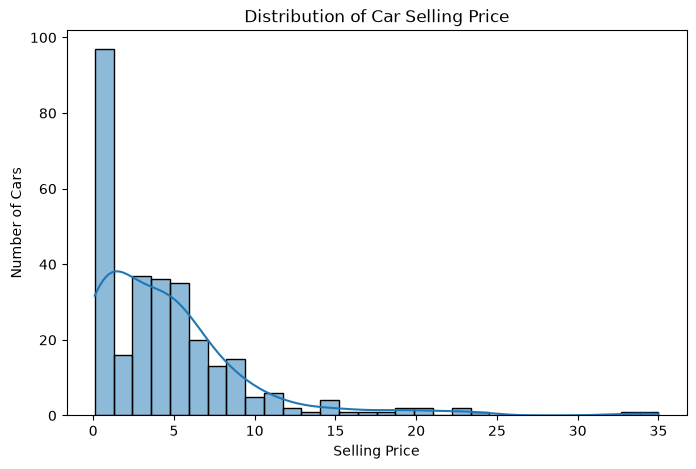

In [13]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Selling_Price"],
    bins=30,
    kde=True
)

plt.title("Distribution of Car Selling Price")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.show()

Selling Price vs Fuel Type

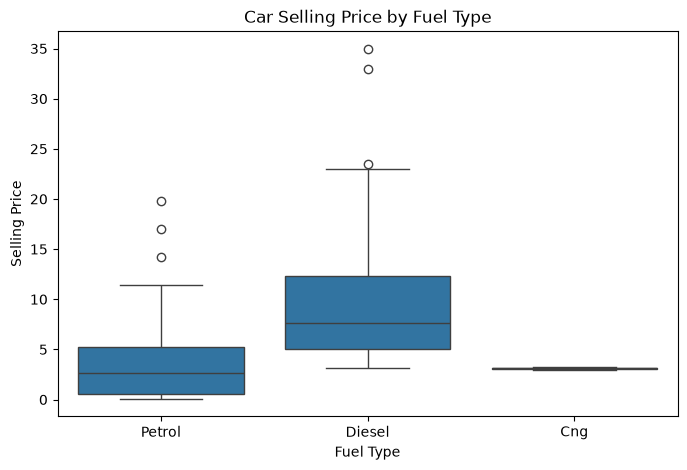

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Fuel_Type",
    y="Selling_Price"
)

plt.title("Car Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")

plt.show()

Selling Price vs Car Age

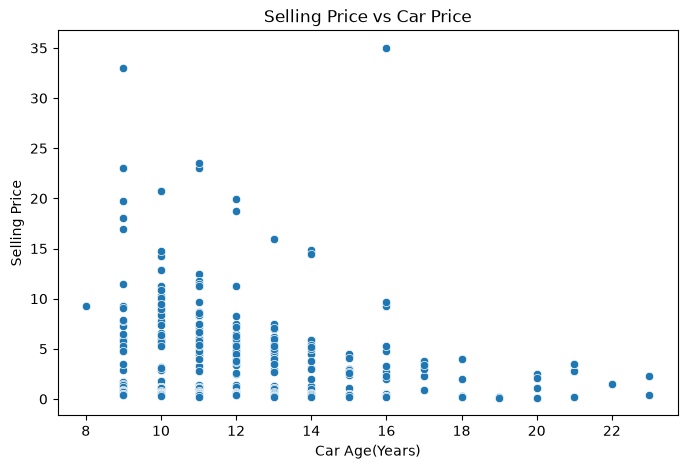

In [15]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Car_Age",
    y="Selling_Price"
)

plt.title("Selling Price vs Car Price")
plt.xlabel("Car Age(Years)")
plt.ylabel("Selling Price")

plt.show()

Correlation Heatmap

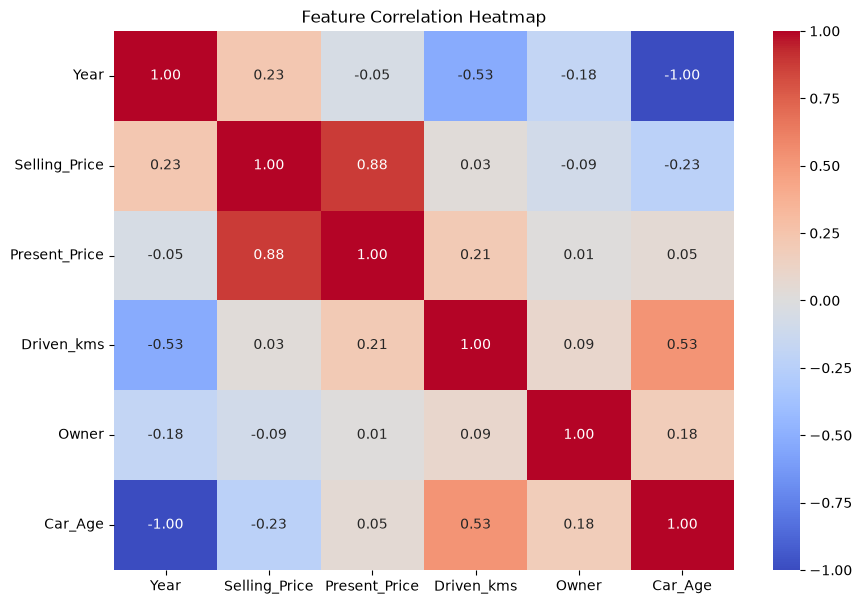

In [16]:
#Select Numerical Columns
numerical_data=df.select_dtypes(include=np.number)

#Calculate Correlation
correlation=numerical_data.corr()

#Plot heatmap
plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

Data Preparation

In [17]:
X=df[
    [
        "Brand",
        "Car_Age",
        "Present_Price",
        "Driven_kms",
        "Fuel_Type",
        "Selling_type",
        "Transmission",
        "Owner"
    ]
]

#Select target variable
y=df["Selling_Price"]

#Split Data into Training and Testing Sets
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (239, 8)
Testing Data: (60, 8)


Encode Categorical Variables

In [18]:
#Identify Numerical and Categorical Columns
numerical_features=X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features=X.select_dtypes(
    exclude=np.number
).columns.tolist()

#Prepare  Numerical Data
numerical_transformer=Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

#Prepare Categorical Data

categorical_transformer=Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

#Combine Both Preprocessing Steps
preprocessor=ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Car_Age', 'Present_Price', 'Driven_kms', 'Owner']
Categorical Features: ['Brand', 'Fuel_Type', 'Selling_type', 'Transmission']


Train Linear Regression Model

In [19]:
linear_model=Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [20]:
#Train the Model
linear_model.fit(X_train, y_train)

#Predict Car Prices
linear_predictions=linear_model.predict(X_test)

print("Linear Regression Model Trained Successfully")

Linear Regression Model Trained Successfully


Train Random Forest Regressor

In [21]:
random_forest_model=Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]
)

#Train The Model
random_forest_model.fit(X_train, y_train)

#Predict Car Prices
rf_predictions=random_forest_model.predict(X_test)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


Model Evaluation

In [22]:
#Evaluate Linear Regression
linear_mae=mean_absolute_error(y_test, linear_predictions)
linear_rms=np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2=r2_score(y_test, linear_predictions)

#Evaluate Random Forest
rf_mae=mean_absolute_error(y_test, rf_predictions)
rf_rmse=np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2=r2_score(y_test, rf_predictions)

#Compare Both Models
results=pd.DataFrame({
    "Model":["Linear Regression", "Random Forest"],
    "MAE":[linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R2 Score": [linear_r2, rf_r2]
})

print(results)

NameError: name 'linear_rmse' is not defined

Compare Model Performance

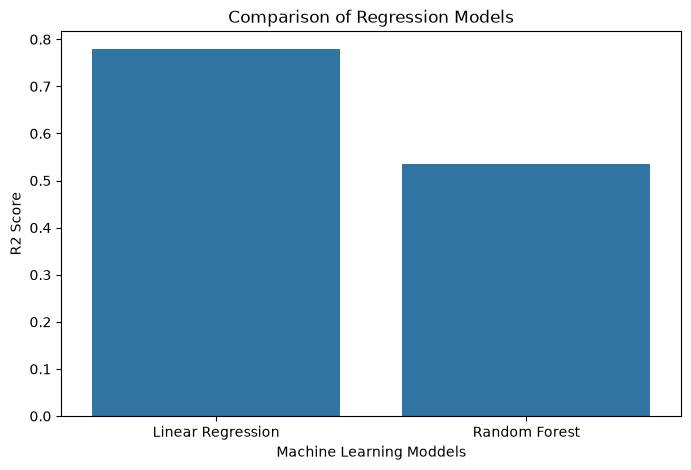

In [ ]:
#Comparison Chart
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.title("Comparison of Regression Models")
plt.xlabel("Machine Learning Moddels")
plt.ylabel("R2 Score")

plt.show()


In [ ]:
#Select the Best-Performing Model using R2 Score
if linear_r2 >= rf_r2:
    best_model = linear_model
    best_predictions=linear_predictions
    best_model_name="Linear Regression"

else:
    best_model=random_forest_model
    best_predictions=rf_predictions
    best_model_name="Random Forest"

print("Best Performing Model:", best_model_name)

Best Performing Model: Linear Regression


Feature Importance Chart

In [ ]:
#Calculate Features Importance
importance=permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2"
)

#Feature Importance DataFrame
importance_df=pd.DataFrame({
    "Feature": X_test.columns,
    "Importance":importance.importances_mean
})

#Sort Features by Importance
importance_df=importance_df.sort_values(
    by="Importance",
    ascending=False
)



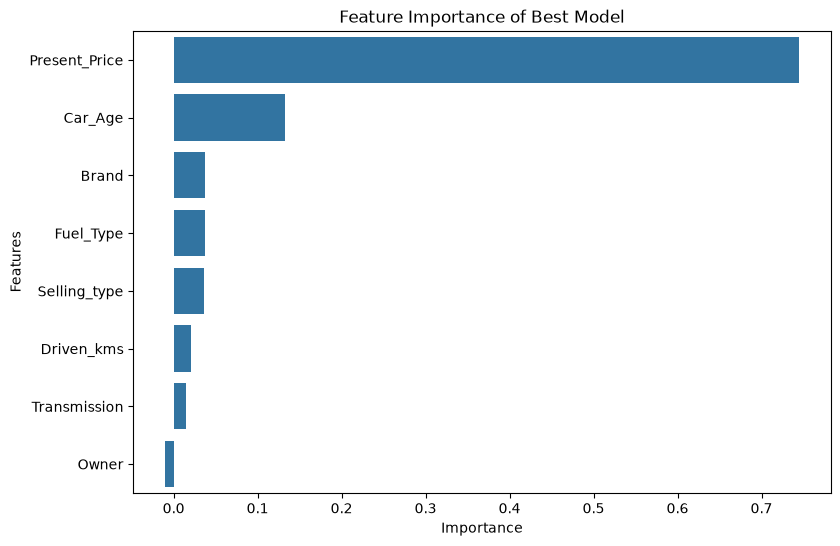

         Feature  Importance
2  Present_Price    0.744823
1        Car_Age    0.132033
0          Brand    0.037870
4      Fuel_Type    0.037477
5   Selling_type    0.036407
3     Driven_kms    0.020860
6   Transmission    0.015148
7          Owner   -0.010190


In [ ]:
#Plot Features Importance 
plt.figure(figsize=(9,6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance of Best Model")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

print(importance_df)

Predict Price Of New Car

In [ ]:
#Details Of New Car
new_car=pd.DataFrame({
    "Brand":["Honda"],
    "Car_Age":[5],
    "Present_Price":[8.0],
    "Driven_kms":[40000],
    "Fuel_Type":["Petrol"],
    "Selling_type":["Dealer"],
    "Transmission":["Manual"],
    "Owner":[0]
})

#Predict Selling Price
predicted_price=best_model.predict(new_car)

print("Predicted Car Selling Price:",
     round(predicted_price[0], 2))

Predicted Car Selling Price: 6.48
